# Experiment 6 — Stopword removal in BM25F

**Comparison:** Stemming with vs without Whoosh English stopword removal. Fixed retrieval depth = 100; Discounted CombSUM; top 10 researchers.

**Caution:** known-positive judgments are incomplete, and related queries may share a source article. Bootstrap results are exploratory.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Notebook works either next to bm25_stopword_results/ or next to the uploaded CSVs.
CANDIDATES = [Path("bm25_stopword_results"), Path("."), Path("/mnt/data")]
FILES = {
    "summary": ["summary.csv", "summary(2).csv"],
    "metrics": ["metrics.csv", "metrics(3).csv"],
    "rankings": ["rankings.csv", "rankings(2).csv"],
    "comparison": ["comparison.csv", "comparison(2).csv"],
    "config": ["run_config.json", "run_config(3).json"],
}
def find_file(names):
    for folder in CANDIDATES:
        for name in names:
            p = folder / name
            if p.exists(): return p
    raise FileNotFoundError(f"Cannot find {names}; set CANDIDATES to your results folder")

paths = {key: find_file(names) for key, names in FILES.items()}
summary = pd.read_csv(paths["summary"])
metrics = pd.read_csv(paths["metrics"])
rankings = pd.read_csv(paths["rankings"])
comparison = pd.read_csv(paths["comparison"])
config = json.loads(paths["config"].read_text())

OUT = Path("bm25_stopword_plots")
OUT.mkdir(exist_ok=True)
ORDER = ["stemming_no_stopwords", "stemming_with_stopwords"]
LABELS = {"stemming_no_stopwords": "Without stopwords", "stemming_with_stopwords": "With stopwords"}
COLORS = {ORDER[0]: "#4472A5", ORDER[1]: "#E28C48"}
METRIC_LABELS = {"known_recall_at_k": "Known-positive Recall@10", "known_mrr_at_k": "Known-positive MRR@10", "known_ndcg_at_k": "Known-positive nDCG@10"}

def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=220, bbox_inches="tight")
    plt.show()

print("Files:")
for k, p in paths.items(): print(f"  {k}: {p}")
print("Queries:", metrics.query_id.nunique(), "| Variants:", metrics.variant.unique().tolist())
display(summary)


Files:
  summary: bm25_stopword_results/summary.csv
  metrics: bm25_stopword_results/metrics.csv
  rankings: bm25_stopword_results/rankings.csv
  comparison: bm25_stopword_results/comparison.csv
  config: bm25_stopword_results/run_config.json
Queries: 452 | Variants: ['stemming_no_stopwords', 'stemming_with_stopwords']


,variant,query_type,queries,known_recall_at_k,known_mrr_at_k,known_ndcg_at_k
0,stemming_no_stopwords,academic,226,0.546091,0.332027,0.370284
1,stemming_no_stopwords,overall,452,0.445133,0.281262,0.309501
2,stemming_no_stopwords,student_style,226,0.344174,0.230498,0.248717
3,stemming_with_stopwords,academic,226,0.536726,0.337252,0.373765
4,stemming_with_stopwords,overall,452,0.468289,0.306942,0.333218
5,stemming_with_stopwords,student_style,226,0.399853,0.276631,0.292671


## 1. Overall effectiveness
The three primary known-positive metrics, using the same evaluation definitions as previous experiments.

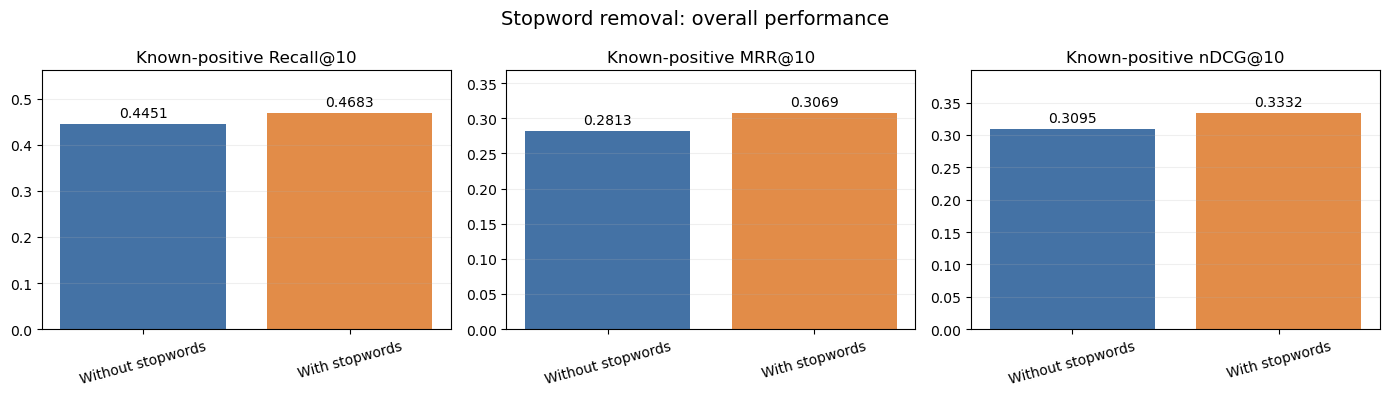

,without,with,absolute_change,relative_change_%
known_recall_at_k,0.445133,0.468289,0.023156,5.202121
known_mrr_at_k,0.281262,0.306942,0.02568,9.130097
known_ndcg_at_k,0.309501,0.333218,0.023717,7.663038


In [2]:
overall = summary[summary.query_type == "overall"].set_index("variant").loc[ORDER]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (col, title) in zip(axes, METRIC_LABELS.items()):
    vals = overall[col]
    bars = ax.bar([LABELS[x] for x in ORDER], vals, color=[COLORS[x] for x in ORDER])
    ax.bar_label(bars, fmt="%.4f", padding=3)
    ax.set_title(title)
    ax.set_ylim(0, max(vals) * 1.20 if max(vals) else 1)
    ax.tick_params(axis="x", labelrotation=15)
    ax.grid(axis="y", alpha=.2)
fig.suptitle("Stopword removal: overall performance", fontsize=14)
savefig("01_overall_metrics.png")

deltas = pd.DataFrame({"without": overall.loc[ORDER[0], list(METRIC_LABELS)],
                       "with": overall.loc[ORDER[1], list(METRIC_LABELS)]})
deltas["absolute_change"] = deltas["with"] - deltas["without"]
deltas["relative_change_%"] = np.where(deltas["without"] != 0, 100*deltas["absolute_change"]/deltas["without"], np.nan)
display(deltas.round(5))

## 2. Academic versus student-style queries
Check whether the impact of stopword removal differs by query type.

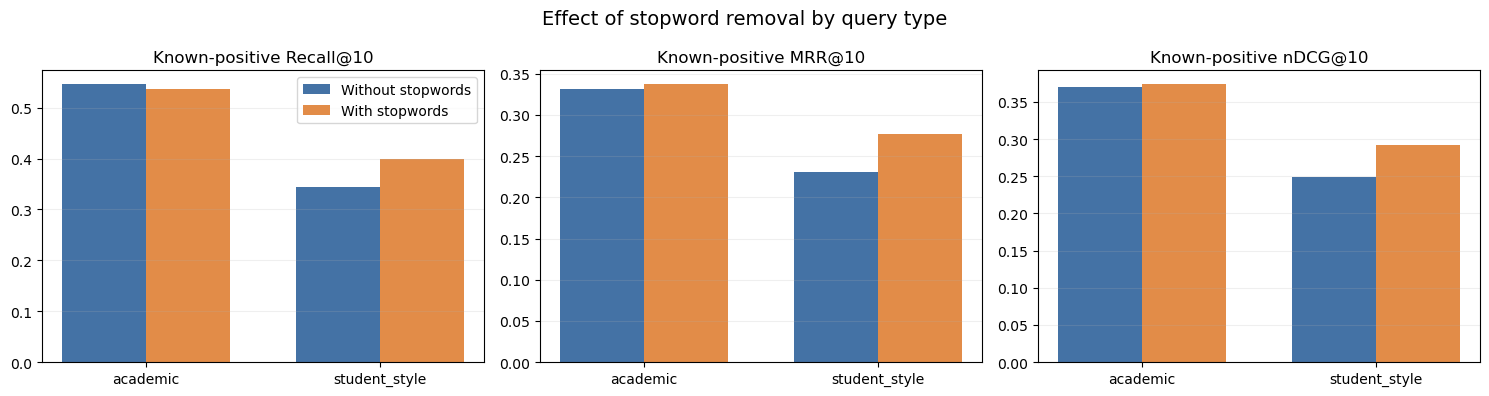

variant,stemming_no_stopwords,stemming_with_stopwords,delta_with_minus_without
query_type,,,
academic,0.37028,0.37376,0.00348
overall,0.30950,0.33322,0.02372
student_style,0.24872,0.29267,0.04395


In [3]:
types = [x for x in summary.query_type.unique() if x != "overall"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (col, title) in zip(axes, METRIC_LABELS.items()):
    x = np.arange(len(types)); width = .36
    for i, variant in enumerate(ORDER):
        vals = [summary.loc[(summary.variant == variant) & (summary.query_type == t), col].iloc[0] for t in types]
        ax.bar(x + (i-.5)*width, vals, width, label=LABELS[variant], color=COLORS[variant])
    ax.set_xticks(x, types)
    ax.set_title(title)
    ax.grid(axis="y", alpha=.2)
axes[0].legend()
fig.suptitle("Effect of stopword removal by query type", fontsize=14)
savefig("02_by_query_type.png")

by_type = summary.pivot(index="query_type", columns="variant", values="known_ndcg_at_k")
by_type["delta_with_minus_without"] = by_type[ORDER[1]] - by_type[ORDER[0]]
display(by_type.round(5))

## 3. Per-query nDCG changes
Paired comparisons reveal whether the average change is driven by a few queries or many.

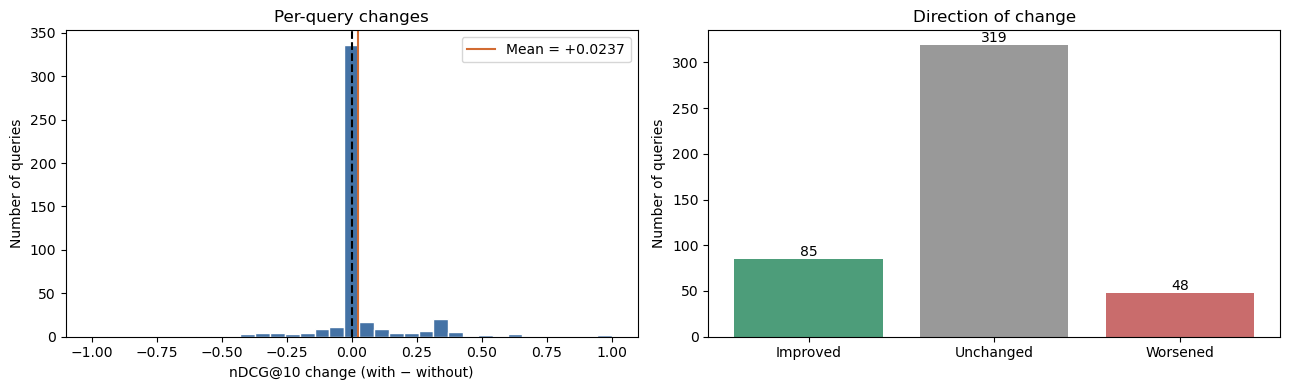

,queries
Improved,85
Unchanged,319
Worsened,48


In [4]:
paired = metrics.pivot(index="query_id", columns="variant", values="known_ndcg_at_k").dropna(subset=ORDER)
paired["delta"] = paired[ORDER[1]] - paired[ORDER[0]]
query_info = metrics.drop_duplicates("query_id").set_index("query_id")[["query", "query_type"]]
paired = paired.join(query_info)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(paired.delta, bins=35, color="#4472A5", edgecolor="white")
axes[0].axvline(0, color="black", linestyle="--")
axes[0].axvline(paired.delta.mean(), color="#D26B32", label=f"Mean = {paired.delta.mean():+.4f}")
axes[0].set(xlabel="nDCG@10 change (with − without)", ylabel="Number of queries", title="Per-query changes")
axes[0].legend()

counts = pd.Series({"Improved": (paired.delta > 1e-12).sum(), "Unchanged": (paired.delta.abs() <= 1e-12).sum(), "Worsened": (paired.delta < -1e-12).sum()})
bars = axes[1].bar(counts.index, counts.values, color=["#4D9D7A", "#999999", "#C96C6C"])
axes[1].bar_label(bars)
axes[1].set(ylabel="Number of queries", title="Direction of change")
savefig("03_per_query_changes.png")
display(counts.to_frame("queries"))

## 4. Ranking stability
Overlap is the number of shared researchers in the top 10; same-top-1 indicates whether the first-ranked researcher stayed the same.

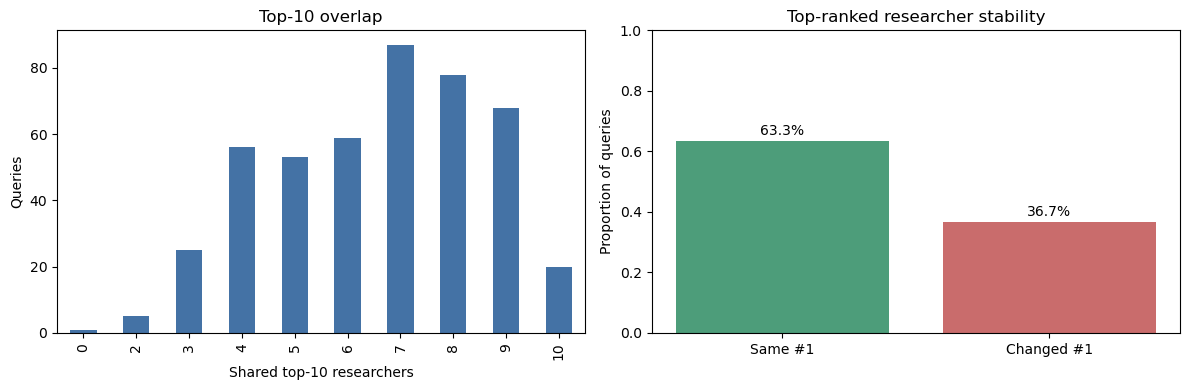

Average top-10 overlap: 6.58/10
Same top-ranked researcher: 63.3%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
comparison.top_k_overlap.value_counts().sort_index().plot(kind="bar", ax=axes[0], color="#4472A5")
axes[0].set(xlabel="Shared top-10 researchers", ylabel="Queries", title="Top-10 overlap")
rate = comparison.same_top_1.mean()
axes[1].bar(["Same #1", "Changed #1"], [rate, 1-rate], color=["#4D9D7A", "#C96C6C"])
axes[1].set_ylim(0, 1)
axes[1].set(ylabel="Proportion of queries", title="Top-ranked researcher stability")
for i, v in enumerate([rate, 1-rate]): axes[1].text(i, v+.02, f"{v:.1%}", ha="center")
savefig("04_ranking_stability.png")
print(f"Average top-10 overlap: {comparison.top_k_overlap.mean():.2f}/10")
print(f"Same top-ranked researcher: {rate:.1%}")

## 5. Retrieved document counts
If stopword removal changes the number of documents retrieved (particularly for conversational queries), that can explain some changes in rankings.

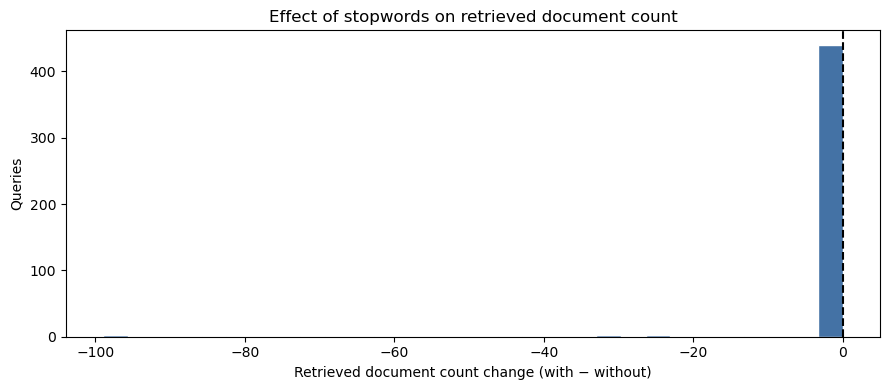

Mean documents without: 100.0
Mean documents with: 98.64


In [6]:
doc_counts = metrics.pivot(index="query_id", columns="variant", values="retrieved_document_count").dropna(subset=ORDER)
doc_counts["delta"] = doc_counts[ORDER[1]] - doc_counts[ORDER[0]]
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(doc_counts.delta, bins=30, color="#4472A5", edgecolor="white")
ax.axvline(0, color="black", linestyle="--")
ax.set(xlabel="Retrieved document count change (with − without)", ylabel="Queries", title="Effect of stopwords on retrieved document count")
savefig("05_document_counts.png")
print("Mean documents without:", round(doc_counts[ORDER[0]].mean(), 2))
print("Mean documents with:", round(doc_counts[ORDER[1]].mean(), 2))

## 6. Biggest improvements and regressions
Inspect the queries most affected by stopword removal. These are useful qualitative examples for the thesis.

In [7]:
columns = ["query_type", "query", ORDER[0], ORDER[1], "delta"]
print("Largest improvements")
display(paired.sort_values("delta", ascending=False)[columns].head(12).round(4))
print("Largest regressions")
display(paired.sort_values("delta")[columns].head(12).round(4))

# Optional: compare top-ranked experts for a selected query ID.
QUERY_ID = int(paired.delta.abs().idxmax())
print(f"Largest absolute change: query {QUERY_ID} — {paired.loc[QUERY_ID, 'query']}")
for variant in ORDER:
    print("\n", LABELS[variant])
    display(rankings[(rankings.query_id == QUERY_ID) & (rankings.variant == variant)][["rank", "researcher_name", "known_positive"]].head(10))

Largest improvements


,query_type,query,stemming_no_stopwords,stemming_with_stopwords,delta
query_id,,,,,
182,student_style,How could I use or study center climate in a u...,0.0000,1.0000,1.0000
250,student_style,How could I use or study climate crisis in a u...,0.0000,1.0000,1.0000
280,student_style,How could I use or study climate initiatives i...,0.0000,0.6309,0.6309
124,student_style,How could I use or study recruitment process i...,0.0000,0.6131,0.6131
118,student_style,How could I use or study hate speech in a univ...,0.0000,0.6131,0.6131
147,academic,Financial times and big things,0.4307,1.0000,0.5693
294,student_style,How could I use or study training program in a...,0.0000,0.5000,0.5000
412,student_style,How could I use or study ethos lab in a univer...,0.0000,0.5000,0.5000
190,student_style,How could I use or study cooperative enterpris...,0.0000,0.4162,0.4162


Largest regressions


,query_type,query,stemming_no_stopwords,stemming_with_stopwords,delta
query_id,,,,,
209,academic,Brit ross and ross winthereik,1.0000,0.0000,-1.0000
323,academic,Want change and used real,0.6309,0.0000,-0.6309
349,academic,Irina shklovski and virt eu,0.5000,0.0000,-0.5000
56,student_style,Can AI predict what someone will do from brain...,0.4307,0.0000,-0.4307
420,student_style,How could I use or study art culture in a univ...,0.6509,0.2641,-0.3869
240,student_style,How could I use or study personal data in a un...,0.3869,0.0000,-0.3869
288,student_style,How could I use or study data scientists in a ...,0.3869,0.0000,-0.3869
403,academic,Health care and example communication,1.0000,0.6309,-0.3691
87,academic,Social groups and lecture watch,0.3562,0.0000,-0.3562


Largest absolute change: query 182 — How could I use or study center climate in a university project?

 Without stopwords


,rank,researcher_name,known_positive
3620,1,Jesper Bengtson,0
3621,2,Irina Papazu,0
3622,3,Toine Bogers,0
3623,4,Yvonne Dittrich,0
3624,5,Andres Faina,0
3625,6,Luca Maria Aiello,0
3626,7,Rob van der Goot,0
3627,8,Willard Rafnsson,0
3628,9,Laurens Boer,0
3629,10,Cancan Wang,0



 With stopwords


,rank,researcher_name,known_positive
3630,1,Steffen Dalsgaard,1
3631,2,Megan Lynn Maurer,0
3632,3,Yvonne Dittrich,0
3633,4,Luca Maria Aiello,0
3634,5,Rune Møller Jensen,0
3635,6,Irina Papazu,0
3636,7,James Maguire,0
3637,8,Claus Brabrand,0
3638,9,Nanna Inie,0
3639,10,Lene Nielsen,0


## 7. Paired bootstrap — uncertainty in nDCG@10 difference
10,000 query-level resamples with fixed seed. **Caution:** query-level resampling ignores shared source articles and is exploratory. An interval crossing zero does not establish equivalence.

Mean paired nDCG@10 difference: +0.02372
95% bootstrap percentile CI: [+0.00923, +0.03855]
95% interval excludes zero: True


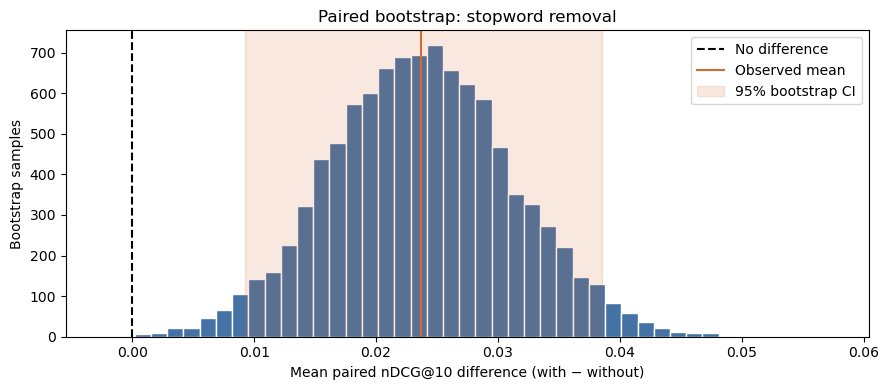

In [8]:
rng = np.random.default_rng(42)
diff = paired.delta.to_numpy()
N = 10_000
boot = np.empty(N)
for i in range(N):
    boot[i] = rng.choice(diff, size=len(diff), replace=True).mean()
ci = np.percentile(boot, [2.5, 97.5])
print(f"Mean paired nDCG@10 difference: {diff.mean():+.5f}")
print(f"95% bootstrap percentile CI: [{ci[0]:+.5f}, {ci[1]:+.5f}]")
print("95% interval excludes zero:", bool(ci[0] > 0 or ci[1] < 0))

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(boot, bins=45, color="#4472A5", edgecolor="white")
ax.axvline(0, color="black", linestyle="--", label="No difference")
ax.axvline(diff.mean(), color="#D26B32", label="Observed mean")
ax.axvspan(ci[0], ci[1], alpha=.15, color="#D26B32", label="95% bootstrap CI")
ax.set(xlabel="Mean paired nDCG@10 difference (with − without)", ylabel="Bootstrap samples", title="Paired bootstrap: stopword removal")
ax.legend()
savefig("06_bootstrap_ndcg.png")

## 8. Export comparison tables and automatic summary

In [9]:
deltas.to_csv(OUT / "overall_metric_changes.csv")
by_type.to_csv(OUT / "ndcg_by_query_type.csv")
paired.to_csv(OUT / "per_query_ndcg_changes.csv")

change = deltas.loc["known_ndcg_at_k", "absolute_change"]
print(f"Stopword removal changed overall known-positive nDCG@10 by {change:+.4f}.")
print(f"Queries improved: {(paired.delta > 1e-12).sum()}, worsened: {(paired.delta < -1e-12).sum()}, unchanged: {(paired.delta.abs() <= 1e-12).sum()}.")
print(f"The query-level 95% bootstrap interval is [{ci[0]:+.4f}, {ci[1]:+.4f}].")
print("Figures and tables saved to:", OUT.resolve())

Stopword removal changed overall known-positive nDCG@10 by +0.0237.
Queries improved: 85, worsened: 48, unchanged: 319.
The query-level 95% bootstrap interval is [+0.0092, +0.0385].
Figures and tables saved to: /Users/izahetmanowska/Desktop/ExpertsSearchEngine/testing/bm25_stopword_plots


## Interpretation notes

- Compare the overall and query-type results before deciding whether to enable stopword removal.
- Use per-query regressions to check whether removing terms changes the intended meaning.
- Do not treat unlabelled researchers as irrelevant: these metrics use incomplete known-positive judgments.
- Because the same queries have been used to tune earlier parameters, this is **exploratory**, not a final held-out evaluation.

### Conclusions

I compared BM25F with and without stopword removal, keeping stemming, Discounted CombSUM and the retrieval cutoff of 100 documents fixed.

**Overall, stopword removal improved retrieval performance across all three metrics:**

- Recall@10 increased from 0.4451 to 0.4683.
- MRR@10 increased from 0.2813 to 0.3069.
- nDCG@10 increased from 0.3095 to 0.3332, an improvement of approximately 7.7%.

The improvement was particularly noticeable for **student-style queries**, where nDCG@10 increased from 0.2487 to 0.2927. Academic queries showed a much smaller improvement, from 0.3703 to 0.3738. This suggests that removing common words is especially useful for longer, more conversational queries, as it allows the search engine to focus more on the meaningful terms.

Looking at individual queries, 85 improved, 48 worsened and 319 remained unchanged. Stopword removal also affected the rankings quite substantially, with an average top-10 overlap of 6.58 researchers and the same top-ranked researcher in 63.3% of queries.

I also performed a paired bootstrap test with 10,000 iterations. The mean improvement in nDCG@10 was +0.0237, with a 95% confidence interval of [0.0092, 0.0386]. Since the interval does not include zero, the results provide evidence of an overall improvement, although the test does not account for dependencies between queries originating from the same articles.

**Decision:** I will keep stopword removal enabled for the next experiments, alongside stemming and Discounted CombSUM. It improves overall performance, particularly for student-style queries. However, some individual queries perform worse, so the effects of removing potentially meaningful words should still be considered.